# Analyzing Crime in Los Angeles (Python)

**Goal:** identify patterns in crime data to help the Los Angeles Police Department (LAPD) allocate resources:
1. At what time of day do most crimes happen?
2. Which area has the most night-time crimes (10pm–4am)?
3. How are crimes distributed across victim age groups?

**Tools:** Python (pandas, NumPy, Matplotlib, Seaborn).
**Data:** `crimes.csv`, ~186,000 crimes reported in 2020–2023 (modified version of the public [Los Angeles Open Data](https://data.lacity.org/) dataset). The file is not included in this repo because of its size (27 MB).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# TIME OCC is read as text to keep leading zeros (e.g. "0130")
crimes = pd.read_csv("crimes.csv", dtype={"TIME OCC": str})
print(crimes.shape)
crimes.head()

(185715, 12)


,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA NAME,Crm Cd Desc,Vict Age,Vict Sex,Vict Descent,Weapon Desc,Status Desc,LOCATION
0,220314085,2022-07-22,2020-05-12,1110,Southwest,THEFT OF IDENTITY,27,F,B,NaN,Invest Cont,2500 S SYCAMORE AV
1,222013040,2022-08-06,2020-06-04,1620,Olympic,THEFT OF IDENTITY,60,M,H,NaN,Invest Cont,3300 SAN MARINO ST
2,220614831,2022-08-18,2020-08-17,1200,Hollywood,THEFT OF IDENTITY,28,M,H,NaN,Invest Cont,1900 TRANSIENT
3,231207725,2023-02-27,2020-01-27,0635,77th Street,THEFT OF IDENTITY,37,M,H,NaN,Invest Cont,6200 4TH AV
4,220213256,2022-07-14,2020-07-14,0900,Rampart,THEFT OF IDENTITY,79,M,B,NaN,Invest Cont,1200 W 7TH ST


## 1. Crimes by hour of the day

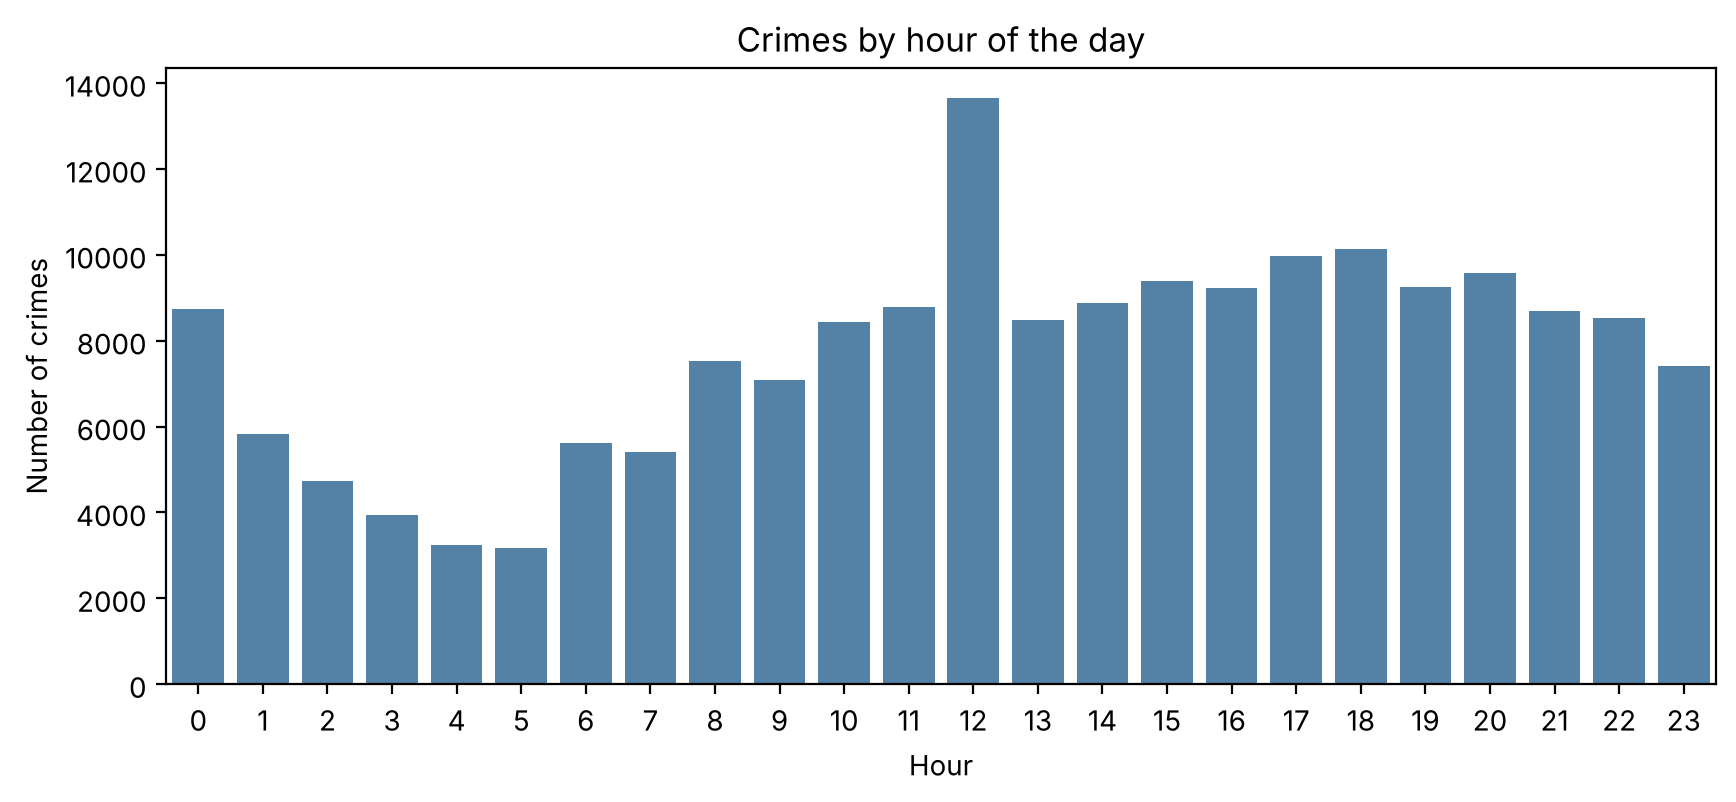

Peak crime hour: 12:00


In [2]:
crimes["hour"] = crimes["TIME OCC"].str[:2].astype(int)

plt.figure(figsize=(10, 4))
sns.countplot(data=crimes, x="hour", color="steelblue")
plt.title("Crimes by hour of the day")
plt.xlabel("Hour")
plt.ylabel("Number of crimes")
plt.show()

peak_crime_hour = crimes["hour"].value_counts().idxmax()
print(f"Peak crime hour: {peak_crime_hour}:00")

## 2. Area with the most night-time crimes (10pm – 4am)

In [3]:
night_crime = crimes.query("hour >= 22 or hour < 4")
night_by_area = night_crime["AREA NAME"].value_counts()

peak_night_crime_location = night_by_area.idxmax()
print(f"Area with most night crimes: {peak_night_crime_location}")
night_by_area.head(5)

Area with most night crimes: Central


AREA NAME
Central        3312
Hollywood      2699
77th Street    2558
Southwest      2347
Southeast      2218
Name: count, dtype: int64

## 3. Crimes by victim age group

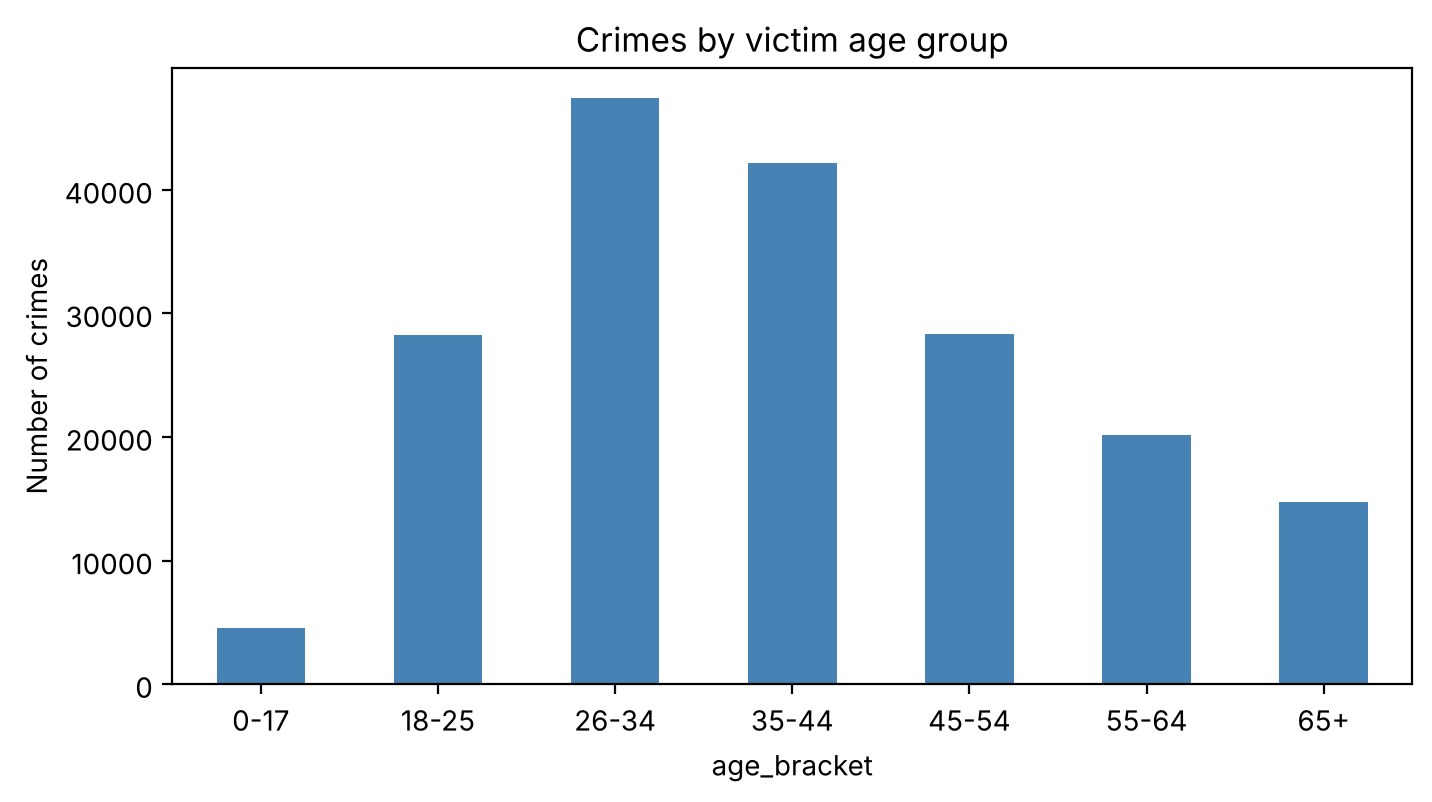

age_bracket
0-17      4528
18-25    28291
26-34    47470
35-44    42157
45-54    28353
55-64    20169
65+      14747
Name: count, dtype: int64

In [4]:
age_bins = [0, 18, 26, 35, 45, 55, 65, np.inf]
age_labels = ["0-17", "18-25", "26-34", "35-44", "45-54", "55-64", "65+"]

# right=False -> intervals [a, b), so an 18-year-old falls in "18-25"
crimes["age_bracket"] = pd.cut(crimes["Vict Age"], bins=age_bins,
                               labels=age_labels, right=False)
victim_ages = crimes["age_bracket"].value_counts().sort_index()

victim_ages.plot(kind="bar", color="steelblue", figsize=(8, 4), rot=0,
                 title="Crimes by victim age group")
plt.ylabel("Number of crimes")
plt.show()

victim_ages

## Conclusions

- **Peak hour is 12:00 (noon)**, with ~13,700 crimes, followed by the evening (17:00–18:00). The spike at exactly 12:00 is much higher than the hours around it, which may partly reflect crimes recorded with a default time when the exact time is unknown, so it would be worth checking with the LAPD.
- **Central is the hotspot at night**, with ~3,300 crimes between 10pm and 4am, followed by Hollywood and 77th Street. Night patrols should prioritize these areas.
- **Victims aged 26–44 are the most affected** (~90,000 crimes combined), with 26–34 being the largest group. Prevention campaigns could focus on young working adults.